In [1]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END

In [2]:
class AgentState(TypedDict):
    n1: int
    op: str
    n2: int
    res: int

In [3]:
def add(state: AgentState) -> AgentState:
    state["res"] = state["n1"] + state["n2"]
    return state

In [4]:
def sub(state: AgentState) -> AgentState:
    state["res"] = state["n1"] - state["n2"]
    return state

In [7]:
def decider(state: AgentState):
    if state["op"] == "+":
        return "add"
    else:
        return "sub"

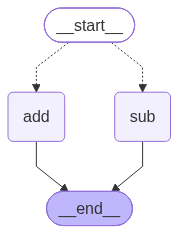

In [13]:
graph = StateGraph(AgentState)

graph.add_node("add", add)
graph.add_node("sub", sub)

graph.add_conditional_edges(
    START,
    decider,
    {
        "add": "add",
        "sub": "sub",
    },
)

graph.add_edge("add", END)
graph.add_edge("sub", END)
app = graph.compile()
app

In [17]:
result = app.invoke({"n1": 1, "n2": 2, "op": '-'})
result

{'n1': 1, 'op': '-', 'n2': 2, 'res': -1}